# Etapa II - EDA y verificación

## Índice
1. Importación, constantes y funciones de control
2. Exploración del original: nulos, repetidos, coordenadas, departamentos
3. Limpieza regla por regla, con registro de cada celda modificada
4. Marcas: visibilidad, posibles duplicados y coordenadas sospechosas
5. Construcción y verificación del dataset limpio
6. Exportación verificada: parquet, manifiesto y registro de cambios
7. Calidad después de la limpieza, frescura y tipo de sitio
8. Mapa de contenedores
9. Un DataFrame por departamento
10. Conclusiones

**Alcance:** diagnóstico y limpieza conservadora de `containers-2022-07-27.csv` (ubicación e información de los contenedores de ¿Dónde Reciclo?, foto del catálogo del 27/07/2022). No se borra ninguna fila ni se inventan valores.

**Qué representa una fila:** un contenedor, identificado por `Id`. Un mismo local puede tener varios contenedores, por eso hay filas con las mismas coordenadas.

**Cómo se puede seguir cada resultado:**
- La huella SHA-256 del CSV se compara con la registrada en la Etapa I, antes y después de la limpieza.
- Cada regla de limpieza deja una fila por celda modificada en `registro_cambios`, con el valor antes y el valor después.
- Antes de exportar, el código comprueba que **toda** diferencia con el original está en ese registro.
- El parquet se relee y se compara con el DataFrame. El manifiesto guarda huellas, reglas y versiones.
- Las cifras de las conclusiones salen de variables calculadas arriba, no de números escritos a mano.

## 1. Importación, constantes y funciones de control

In [1]:
from datetime import datetime
from pathlib import Path
import hashlib
import json
import platform
import re
import unicodedata

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow
from folium.plugins import MarkerCluster
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# El notebook corre desde: docs/Datos/Análisis de datos/Etapa II - EDA y verificación
CARPETA_NOTEBOOK = Path.cwd()
CARPETA_DATOS = CARPETA_NOTEBOOK.parents[1]  # docs/Datos

ARCHIVO_ORIGINAL = CARPETA_DATOS / "Dataset - original" / "containers-2022-07-27.csv"
ARCHIVO_PROCEDENCIA = ARCHIVO_ORIGINAL.parent / (ARCHIVO_ORIGINAL.stem + ".procedencia.json")

CARPETA_LIMPIO = CARPETA_DATOS / "Dataset - limpio"
ARCHIVO_LIMPIO = CARPETA_LIMPIO / "containers-limpio.parquet"
ARCHIVO_MANIFIESTO = CARPETA_LIMPIO / "containers-limpio.manifiesto.json"
ARCHIVO_CAMBIOS = CARPETA_LIMPIO / "containers-cambios.csv"

ARCHIVO_MAPA = CARPETA_NOTEBOOK / "mapa-contenedores.html"

# El archivo es una foto del catálogo: la frescura se mide contra esta fecha
FECHA_FOTO = pd.Timestamp("2022-07-27", tz="UTC")

# Límites aproximados de Uruguay para validar coordenadas
LAT_MIN, LAT_MAX = -35.1, -30.0
LON_MIN, LON_MAX = -58.5, -53.0

DEPARTAMENTOS = [
    "Artigas", "Canelones", "Cerro Largo", "Colonia", "Durazno", "Flores", "Florida",
    "Lavalleja", "Maldonado", "Montevideo", "Paysandú", "Río Negro", "Rivera", "Rocha",
    "Salto", "San José", "Soriano", "Tacuarembó", "Treinta y Tres",
]

# Columnas de texto que se limpian, y el nombre que tienen en el dataset limpio
TEXTOS = ["Site", "Address", "Location", "State", "Site type", "Information"]
NOMBRES = {
    "Site": "sitio", "Address": "direccion", "Location": "localidad", "State": "departamento",
    "Site type": "tipo_sitio", "Information": "informacion", "Latitude": "latitud", "Longitude": "longitud",
}

CAMBIOS = []  # cada regla agrega aquí una tabla con sus celdas modificadas

In [2]:
def sha256(ruta):
    """Huella SHA-256 de un archivo, leído por bloques."""
    huella = hashlib.sha256()
    with Path(ruta).open("rb") as flujo:
        for bloque in iter(lambda: flujo.read(1024 * 1024), b""):
            huella.update(bloque)
    return huella.hexdigest()


def en_uruguay(lat, lon):
    """True si cada par (lat, lon) cae dentro del rectángulo aproximado de Uruguay."""
    return lat.between(LAT_MIN, LAT_MAX) & lon.between(LON_MIN, LON_MAX)


def km_entre(lat1, lon1, lat2, lon2):
    """Distancia aproximada en km con un plano local; alcanza para Uruguay."""
    return np.hypot((lat1 - lat2) * 111.0, (lon1 - lon2) * 111.0 * np.cos(np.radians(-33)))


def valla_extrema(distancias):
    """Valla de Tukey para atípicos extremos: Q3 + 3 veces el rango intercuartil."""
    q1, q3 = distancias.quantile([0.25, 0.75])
    return q3 + 3 * (q3 - q1)


def atipicos_iqr(serie):
    """Marca los valores fuera de 1.5 veces el rango intercuartil."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)


def perfil_columnas(df):
    """Tipo, nulos, porcentaje de nulos y valores distintos de cada columna."""
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "% nulos": df.isna().mean().mul(100).round(1),
        "distintos": df.nunique(),
    })


def registrar_cambios(regla, columna, antes, despues):
    """Anota una fila por celda modificada (id, valor antes, valor después) y devuelve cuántas son."""
    cambio = ~(antes.eq(despues) | (antes.isna() & despues.isna()))
    if cambio.any():
        CAMBIOS.append(pd.DataFrame({
            "id": df_raw.loc[cambio, "Id"],
            "regla": regla,
            "columna": columna,
            "valor_antes": antes[cambio].astype("string"),
            "valor_despues": despues[cambio].astype("string"),
        }))
    return int(cambio.sum())


def exportar_verificado(df, ruta_parquet, ruta_origen, huella_origen, pasos):
    """Guarda el parquet, lo relee, comprueba que es idéntico y devuelve el manifiesto."""
    ruta_parquet.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(ruta_parquet, index=False)
    releido = pd.read_parquet(ruta_parquet)
    try:
        pd.testing.assert_frame_equal(releido, df)
        identico = True
    except AssertionError:
        identico = False
    return {
        "generado": datetime.now().astimezone().isoformat(timespec="seconds"),
        "origen": {"archivo": ruta_origen.name, "sha256": huella_origen, "bytes": ruta_origen.stat().st_size},
        "salida": {
            "archivo": ruta_parquet.name, "sha256": sha256(ruta_parquet), "bytes": ruta_parquet.stat().st_size,
            "filas": len(df), "columnas": df.shape[1], "nombres_de_columnas": df.columns.tolist(),
        },
        "relectura_identica": identico,
        "reglas_aplicadas": pasos,
        "entorno": {
            "python": platform.python_version(), "pandas": pd.__version__,
            "pyarrow": pyarrow.__version__, "folium": folium.__version__,
        },
    }

In [3]:
# La huella del CSV debe coincidir con la que registró la Etapa I
if not ARCHIVO_PROCEDENCIA.exists():
    raise FileNotFoundError("Falta el archivo de procedencia: ejecutar primero la Etapa I")
procedencia = json.loads(ARCHIVO_PROCEDENCIA.read_text(encoding="utf-8"))
huella_original_antes = sha256(ARCHIVO_ORIGINAL)
assert huella_original_antes == procedencia["sha256"], "El CSV no es el archivo registrado en la Etapa I"

df_raw = pd.read_csv(ARCHIVO_ORIGINAL, encoding="utf-8-sig")  # el archivo trae BOM
filas_originales = len(df_raw)
print(f"Origen: {filas_originales:,} filas; {df_raw['Id'].nunique():,} Id distintos; {df_raw.shape[1]} columnas")
print("SHA-256 del CSV:", huella_original_antes)
print("Procedencia registrada el:", procedencia["fecha_registro"])

Origen: 2,423 filas; 2,423 Id distintos; 16 columnas
SHA-256 del CSV: 01ffdfe84b61c6f5a7d579586d1bbac7283e0fafbf8ab5dca30a1f988a9e8dbf
Procedencia registrada el: 2026-10-29


## 2. Exploración del original

In [4]:
for i, col in enumerate(df_raw.columns, start=1):
    print(f"{i}. {col}")

1. Id
2. External
3. Latitude
4. Longitude
5. Site
6. Address
7. Location
8. State
9. Site type
10. Public site
11. Created at
12. Updated at
13. Hidden
14. Latlon
15. Information
16. Custom icon active


In [5]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2423 entries, 0 to 2422
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Id                  2423 non-null   int64  
 1   External            1598 non-null   float64
 2   Latitude            2423 non-null   float64
 3   Longitude           2422 non-null   float64
 4   Site                2031 non-null   object 
 5   Address             2046 non-null   object 
 6   Location            887 non-null    object 
 7   State               2421 non-null   object 
 8   Site type           1427 non-null   object 
 9   Public site         2423 non-null   bool   
 10  Created at          2423 non-null   object 
 11  Updated at          2423 non-null   object 
 12  Hidden              2423 non-null   bool   
 13  Latlon              0 non-null      float64
 14  Information         169 non-null    object 
 15  Custom icon active  198 non-null    object 
dtypes: boo

In [6]:
df_raw.head(3)

,Id,External,Latitude,Longitude,Site,Address,Location,State,Site type,Public site,Created at,Updated at,Hidden,Latlon,Information,Custom icon active
0,11780,NaN,-34.753762,-55.845820,NaN,"Ruta 87, Manzana 157, Solar 16. Entre Tapes y ...",Salinas,Canelones,NaN,True,2022-07-26 20:21:39 UTC,2022-07-26 20:32:15 UTC,False,NaN,Compostar para utilizar en huerta comunitaria ...,False
1,11779,NaN,-34.592136,-54.124148,Club de La Pedrera (martes previa coordinación...,NaN,La Paloma,Rocha,NaN,True,2022-07-25 19:18:50 UTC,2022-07-26 20:33:53 UTC,False,NaN,Se recicla el residuo ferroso y plástico que c...,False
2,11778,NaN,-34.618292,-54.151271,Placita de Arachania (sábados previa coordinac...,NaN,La Paloma,Rocha,NaN,True,2022-07-25 19:13:49 UTC,2022-07-26 20:34:12 UTC,False,NaN,Se recicla el residuo ferroso y plástico que c...,False


### Valores faltantes

Se cuentan los nulos de cada columna. `Latlon` está vacía en todas las filas. Además se comprueba que no haya textos vacíos disfrazados de dato.

In [7]:
perfil_original = perfil_columnas(df_raw)
textos_vacios = int(df_raw[TEXTOS].apply(lambda s: s.str.strip().eq("")).sum().sum())
print("Celdas de texto vacías:", textos_vacios)
perfil_original[perfil_original["nulos"] > 0].sort_values("nulos", ascending=False)

Celdas de texto vacías: 0


,tipo,nulos,% nulos,distintos
Latlon,float64,2423,100.0,0
Information,object,2254,93.0,109
Custom icon active,object,2225,91.8,2
Location,object,1536,63.4,299
Site type,object,996,41.1,36
External,float64,825,34.0,581
Site,object,392,16.2,1277
Address,object,377,15.6,1984
State,object,2,0.1,28
Longitude,float64,1,0.0,2394


### Filas repetidas

Se prueban tres criterios: fila idéntica, `Id` repetido y repetido en contenido (todo salvo `Id`, fechas y `External`). Además se cuentan las filas que comparten coordenadas exactas: puede haber varios contenedores en el mismo local, así que no se interpretan como error.

In [8]:
COLUMNAS_CONTENIDO = ["Latitude", "Longitude", "Site", "Address", "State", "Site type", "Information"]

n_duplicadas_exactas = int(df_raw.duplicated().sum())
n_ids_repetidos = int(df_raw["Id"].duplicated().sum())
n_repetidas_contenido = int(df_raw.duplicated(COLUMNAS_CONTENIDO).sum())
n_comparten_coordenadas = int(df_raw.duplicated(["Latitude", "Longitude"], keep=False).sum())

print("Filas duplicadas exactas:", n_duplicadas_exactas)
print("Ids repetidos:", n_ids_repetidos)
print("Repetidas en contenido (sin Id ni fechas):", n_repetidas_contenido)
print("Filas que comparten coordenadas exactas:", n_comparten_coordenadas)

Filas duplicadas exactas: 0
Ids repetidos: 0
Repetidas en contenido (sin Id ni fechas): 14
Filas que comparten coordenadas exactas: 47


### Departamentos tal como vienen

`repr` deja a la vista los espacios de relleno que no se ven en pantalla. Se espera ver 19 departamentos y se ven más escrituras.

In [9]:
n_departamentos_antes = int(df_raw["State"].nunique())
print("Escrituras distintas de departamento:", n_departamentos_antes)
df_raw["State"].map(repr).value_counts(dropna=False)

Escrituras distintas de departamento: 28


State
'Montevideo'               1275
'Montevideo '               357
'Canelones'                 275
'Colonia'                    70
'Maldonado'                  65
'Paysandú'                   57
'Flores'                     56
'Rocha'                      39
'Tacuarembó'                 33
'Salto'                      31
'Rivera'                     27
'Lavalleja'                  25
'Florida'                    20
'Soriano'                    18
'Cerro Largo'                12
'Artigas'                    11
'San José'                   11
'Treinta y Tres'             11
'Durazno'                    10
'Río Negro'                  10
nan                           2
'Paysandu'                    1
'Soriano '                    1
'San Jose'                    1
'Rio Negro'                   1
'La Floresta-Canelones'       1
'Flroes'                      1
'Tacaurembó'                  1
'Treinta y Tres '             1
Name: count, dtype: int64

### Coordenadas

Cada fila fuera de Uruguay se clasifica en una sola categoría, en este orden: intercambiadas (latitud y longitud al revés), signo positivo en la longitud, un cero, faltante u otras. Las otras se listan para revisarlas una por una.

In [10]:
lat0, lon0 = df_raw["Latitude"], df_raw["Longitude"]

dentro = en_uruguay(lat0, lon0)
es_intercambiada = ~dentro & en_uruguay(lon0, lat0)
es_signo = ~dentro & ~es_intercambiada & (lon0 > 0) & en_uruguay(lat0, -lon0)
es_cero = ~dentro & ~es_intercambiada & ~es_signo & ((lat0 == 0) | (lon0 == 0))
es_faltante = ~dentro & ~es_intercambiada & ~es_signo & ~es_cero & (lat0.isna() | lon0.isna())
es_otra = ~dentro & ~(es_intercambiada | es_signo | es_cero | es_faltante)

n_validas_original = int(dentro.sum())
n_fuera_original = int((~dentro).sum())
n_intercambiadas = int(es_intercambiada.sum())
n_signo = int(es_signo.sum())
n_cero = int(es_cero.sum())
n_faltante = int(es_faltante.sum())
n_otras_fuera = int(es_otra.sum())

anomalias_coordenadas = pd.Series({
    "Dentro de Uruguay": n_validas_original,
    "Fuera de Uruguay o sin coordenadas": n_fuera_original,
    "  latitud y longitud intercambiadas": n_intercambiadas,
    "  longitud con signo positivo": n_signo,
    "  latitud o longitud igual a 0": n_cero,
    "  coordenada faltante": n_faltante,
    "  otras (valores fuera de escala)": n_otras_fuera,
}, name="filas")
assert n_fuera_original == n_intercambiadas + n_signo + n_cero + n_faltante + n_otras_fuera
display(anomalias_coordenadas)
df_raw.loc[es_otra | es_faltante | es_cero, ["Id", "Site", "Location", "State", "Latitude", "Longitude"]]

Dentro de Uruguay                      2372
Fuera de Uruguay o sin coordenadas       51
  latitud y longitud intercambiadas      44
  longitud con signo positivo             1
  latitud o longitud igual a 0            1
  coordenada faltante                     1
  otras (valores fuera de escala)         4
Name: filas, dtype: int64

,Id,Site,Location,State,Latitude,Longitude
5,11775,Piccola Marina,La Paloma,Rocha,-34.655127,-5.417798e+16
53,11727,Barraca Dayman,Salto,Salto,-31.387144,-5.795867e+15
93,11687,Mari Madá Pocitos,Pocitos,Montevideo,-34.912390,0.000000e+00
122,11658,Estación ANCAP,Carrasco,Montevideo,-34.877940,-3.487794e+01
123,11657,Ventas Albion,Buceo,Montevideo,-34.887250,-3.488725e+01
807,3204,Super Ibiza,La Floresta - La Tuna,Canelones,-34.780250,NaN


### Localidades, visibilidad y fechas

- **Localidades:** se cuentan los contenedores por localidad y se marcan las que tienen muchos más que el resto (IQR). Es concentración, no error.
- **Visibilidad:** `Hidden` y `Public site` definen qué ve la API pública.
- **Fechas:** `Created at` y `Updated at` vienen como texto con ` UTC`.

In [11]:
por_localidad_original = df_raw["Location"].value_counts()
n_localidades_antes = int(por_localidad_original.size)
n_localidades_atipicas = int(atipicos_iqr(por_localidad_original).sum())
print("Localidades distintas:", n_localidades_antes)
print("Localidades con muchos contenedores (IQR):", n_localidades_atipicas)
display(por_localidad_original[atipicos_iqr(por_localidad_original)])

display(pd.crosstab(df_raw["Hidden"], df_raw["Public site"], margins=True))

creado_original = pd.to_datetime(df_raw["Created at"].str.replace(" UTC", ""), utc=True)
actualizado_original = pd.to_datetime(df_raw["Updated at"].str.replace(" UTC", ""), utc=True)
print("Actualizado antes que creado:", int((actualizado_original < creado_original).sum()))
print("Rango de creación:", creado_original.min(), "→", creado_original.max())

Localidades distintas: 299
Localidades con muchos contenedores (IQR): 23


Location
Montevideo         64
Colonia            45
Paysandú           44
Trinidad           43
Maldonado          28
Salto              26
Rivera             17
Canelones          13
Mariscala          13
Ismael Cortinas    12
Punta del Este     12
Santa Rosa          9
Santa Lucía         9
San Jacinto         8
Salinas             8
Sauce               8
Las Piedras         8
La Paloma           8
ATLANTIDA           7
CANELONES           7
San Bautista        7
Migues              7
San Ramón           7
Name: count, dtype: int64

Public site,False,True,All
Hidden,,,
False,9,2207,2216
True,0,207,207
All,9,2414,2423


Actualizado antes que creado: 0
Rango de creación: 2020-07-08 21:35:12+00:00 → 2022-07-26 20:21:39+00:00


## 3. Limpieza regla por regla

Cada regla sigue el mismo esquema: **qué se observó, qué se decide y por qué**. El código aplica la regla y llama a `registrar_cambios`, que guarda una fila por celda modificada. Ninguna regla borra filas.

| Regla | Qué hace | Columnas |
|---|---|---|
| R1 | Quita espacios sobrantes y pasa los textos vacíos a faltantes | texto |
| R2 | Unifica la escritura del departamento (tildes, espacios, errores) | `State` |
| R3 | Completa un departamento faltante si su localidad pertenece a uno solo | `State` |
| R4 | Unifica mayúsculas y tildes de la localidad | `Location` |
| R5 | Corrige latitud y longitud intercambiadas | `Latitude`, `Longitude` |
| R6 | Corrige el signo positivo de la longitud | `Longitude` |
| R7 | Quita las coordenadas que siguen fuera de Uruguay | `Latitude`, `Longitude` |

### R1. Espacios sobrantes y textos vacíos

**Observación.** El departamento aparece con y sin espacio al final (`'Montevideo'` y `'Montevideo '`). Python los trata como valores distintos.

**Decisión.** Se aplica `strip` y se colapsan los espacios dobles en las columnas de texto. Los textos vacíos pasan a faltantes.

**Por qué.** Es un cambio de forma, no de contenido: no puede cambiar el significado de ningún valor.

In [12]:
df = df_raw.copy()

celdas_r1 = {}
for col in TEXTOS:
    nuevo = df[col].str.strip().str.replace(r"\s+", " ", regex=True).replace("", np.nan)
    celdas_r1[col] = registrar_cambios("R1 espacios y vacíos", NOMBRES[col], df[col], nuevo)
    df[col] = nuevo

pd.Series(celdas_r1, name="celdas modificadas por R1")

Site            21
Address        153
Location         1
State          359
Site type        0
Information     84
Name: celdas modificadas por R1, dtype: int64

### R2. Escritura del departamento

**Observación.** Después de R1 siguen quedando variantes: sin tilde (`Paysandu`, `San Jose`, `Rio Negro`) y errores de escritura (`Flroes`, `Tacaurembó`, `La Floresta-Canelones`).

**Decisión.** Se compara cada valor con los 19 departamentos reales ignorando tildes y mayúsculas. Los tres errores de escritura se corrigen con una tabla explícita. Todo valor que no se reconozca hace fallar la celda.

**Por qué.** Los 19 departamentos son un conjunto cerrado; una tabla explícita deja a la vista cada corrección y no adivina.

In [13]:
def clave(texto):
    """Nombre en minúsculas, sin tildes ni signos: sirve para comparar variantes."""
    sin_tildes = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^a-z]", "", sin_tildes.lower())


CANONICO = {clave(d): d for d in DEPARTAMENTOS}
ESCRITURAS_ERRONEAS = {
    "Flroes": "Flores",
    "Tacaurembó": "Tacuarembó",
    "La Floresta-Canelones": "Canelones",
}


def normalizar_departamento(valor):
    if pd.isna(valor):
        return np.nan
    if valor in ESCRITURAS_ERRONEAS:
        return ESCRITURAS_ERRONEAS[valor]
    return CANONICO.get(clave(valor), valor)


nuevo = df["State"].map(normalizar_departamento)
celdas_r2 = registrar_cambios("R2 departamento: escritura", NOMBRES["State"], df["State"], nuevo)

# Cada corrección con su cantidad de filas
tabla_r2 = pd.DataFrame({"antes": df["State"], "despues": nuevo}).value_counts(dropna=False).rename("filas").reset_index()
display(tabla_r2[tabla_r2["antes"].fillna("") != tabla_r2["despues"].fillna("")])

df["State"] = nuevo
no_reconocidos = sorted(set(df["State"].dropna()) - set(DEPARTAMENTOS))
assert not no_reconocidos, no_reconocidos
print("Celdas modificadas por R2:", celdas_r2)

,antes,despues,filas
20,La Floresta-Canelones,Canelones,1
21,Flroes,Flores,1
22,Rio Negro,Río Negro,1
23,Paysandu,Paysandú,1
24,San Jose,San José,1
25,Tacaurembó,Tacuarembó,1


Celdas modificadas por R2: 6


### R3. Departamento faltante

**Observación.** Quedan filas sin departamento.

**Decisión.** Si la localidad de la fila aparece en un único departamento en el resto del archivo, se completa con ese. Si no, queda faltante.

**Por qué.** Se usa un dato registrado para la misma localidad y no una suposición. Una localidad ambigua (por ejemplo, el mismo nombre en dos departamentos) no se completa.

In [14]:
faltan_departamento = df["State"].isna()
n_sin_departamento_antes_r3 = int(faltan_departamento.sum())

depto_por_localidad = (
    df.dropna(subset=["State", "Location"])
    .groupby("Location")["State"]
    .agg(lambda s: s.iloc[0] if s.nunique() == 1 else np.nan)
    .dropna()
)

nuevo = df["State"].copy()
nuevo[faltan_departamento] = df.loc[faltan_departamento, "Location"].map(depto_por_localidad)
celdas_r3 = registrar_cambios("R3 departamento: completado por localidad", NOMBRES["State"], df["State"], nuevo)
df["State"] = nuevo

n_sin_departamento = int(df["State"].isna().sum())
print("Sin departamento antes de R3:", n_sin_departamento_antes_r3)
print("Completados por localidad:", celdas_r3)
print("Siguen sin departamento:", n_sin_departamento)
df.loc[df["State"].isna(), ["Id", "Site", "Location", "State"]]

Sin departamento antes de R3: 2
Completados por localidad: 1
Siguen sin departamento: 1


,Id,Site,Location,State
932,3078,Antel Mercado Agrícola,Mercado Agrícola,NaN


### R4. Localidades

**Observación.** La misma localidad aparece con distinta forma (`ATLANTIDA` y `Atlántida`).

**Decisión.** Se agrupan las formas que solo difieren en tildes, mayúsculas o signos, y se usa la más frecuente de cada grupo.

**Por qué.** Evita contar una localidad como varias sin inventar un nombre: siempre se elige una forma que ya existe en el archivo.

In [15]:
formas = df["Location"].dropna().value_counts()
forma_canonica = formas.groupby(formas.index.map(clave)).idxmax()

nuevo = df["Location"].map(lambda v: forma_canonica.get(clave(v), v) if pd.notna(v) else v)
celdas_r4 = registrar_cambios("R4 localidad: mayúsculas y tildes", NOMBRES["Location"], df["Location"], nuevo)

ejemplos_r4 = (
    pd.DataFrame({"antes": df["Location"], "despues": nuevo})
    .query("antes != despues")
    .value_counts()
    .rename("filas")
    .reset_index()
)
df["Location"] = nuevo

n_localidades_despues = int(df["Location"].nunique())
print("Celdas modificadas por R4:", celdas_r4)
print("Localidades distintas:", n_localidades_antes, "→", n_localidades_despues)
ejemplos_r4.head(10)

Celdas modificadas por R4: 70
Localidades distintas: 299 → 261


,antes,despues,filas
0,CANELONES,Canelones,7
1,Atlántida,ATLANTIDA,5
2,LA PAZ,La Paz,3
3,La Floresta,LA FLORESTA,3
4,Carrasco,CARRASCO,3
5,Solymar,SOLYMAR,3
6,TALA,Tala,3
7,SALINAS,Salinas,3
8,Piriapolis,Piriápolis,3
9,PARQUE DEL PLATA,Parque del Plata,3


### R5, R6 y R7. Coordenadas

**Observación.** Los errores de coordenadas son de tres tipos: bloques con latitud y longitud al revés (en Colonia, latitud -57,8 y longitud -34,4), una longitud con signo positivo, y valores fuera de escala (como -5,4e16) o ceros.

**Decisión.**
1. **R5:** si el par está fuera de Uruguay pero al revés cae dentro, se intercambian.
2. **R6:** si la longitud es positiva y con el signo cambiado el par cae dentro, se cambia el signo.
3. **R7:** si el par sigue fuera de Uruguay, se quitan las dos coordenadas. No se inventan.

**Por qué.** R5 y R6 recuperan un valor que ya estaba en la fila, solo mal ubicado. R7 evita mostrar en el mapa un punto que no se puede ubicar. El valor original se conserva en `latitud_original` y `longitud_original`.

In [16]:
# R5: latitud y longitud intercambiadas
lat1 = lat0.where(~es_intercambiada, lon0)
lon1 = lon0.where(~es_intercambiada, lat0)
celdas_r5 = (
    registrar_cambios("R5 coordenadas intercambiadas", NOMBRES["Latitude"], lat0, lat1)
    + registrar_cambios("R5 coordenadas intercambiadas", NOMBRES["Longitude"], lon0, lon1)
)

# R6: longitud con signo positivo
es_signo_r6 = (lon1 > 0) & en_uruguay(lat1, -lon1)
lat2 = lat1
lon2 = lon1.where(~es_signo_r6, -lon1)
celdas_r6 = registrar_cambios("R6 signo de la longitud", NOMBRES["Longitude"], lon1, lon2)

# R7: lo que sigue fuera de Uruguay queda sin coordenadas (las dos, porque el par no es confiable)
valida = en_uruguay(lat2, lon2)
lat3 = lat2.where(valida)
lon3 = lon2.where(valida)
celdas_r7 = (
    registrar_cambios("R7 coordenada fuera de Uruguay", NOMBRES["Latitude"], lat2, lat3)
    + registrar_cambios("R7 coordenada fuera de Uruguay", NOMBRES["Longitude"], lon2, lon3)
)

df["latitud"] = lat3
df["longitud"] = lon3
df["coordenada_valida"] = valida
df["coordenada_corregida"] = np.select(
    [es_intercambiada, es_signo_r6], ["intercambiada", "signo de longitud"], default=""
)
df["coordenada_corregida"] = df["coordenada_corregida"].replace("", np.nan)

n_validas_limpio = int(valida.sum())
n_sin_coordenadas = int((~valida).sum())
n_corregidas_r5 = int(es_intercambiada.sum())
n_corregidas_r6 = int(es_signo_r6.sum())
assert n_corregidas_r5 == n_intercambiadas  # lo corregido es lo que la exploración encontró
print("Filas corregidas por R5:", n_corregidas_r5, "| por R6:", n_corregidas_r6)
print("Coordenadas válidas:", n_validas_original, "→", n_validas_limpio, "| sin coordenadas:", n_sin_coordenadas)
df.loc[~valida, ["Id", "Site", "Location", "State", "Latitude", "Longitude"]]

Filas corregidas por R5:

 44 | por R6: 1
Coordenadas válidas: 2372 → 2417 | sin coordenadas: 6


,Id,Site,Location,State,Latitude,Longitude
5,11775,Piccola Marina,La Paloma,Rocha,-34.655127,-5.417798e+16
53,11727,Barraca Dayman,Salto,Salto,-31.387144,-5.795867e+15
93,11687,Mari Madá Pocitos,Pocitos,Montevideo,-34.912390,0.000000e+00
122,11658,Estación ANCAP,CARRASCO,Montevideo,-34.877940,-3.487794e+01
123,11657,Ventas Albion,Buceo,Montevideo,-34.887250,-3.488725e+01
807,3204,Super Ibiza,La Floresta - La Tuna,Canelones,-34.780250,NaN


### Registro de cambios

Se une el registro de todas las reglas. Cada fila es una celda: el `id` del contenedor, la regla, la columna, el valor antes y el valor después.

In [17]:
registro_cambios = pd.concat(CAMBIOS, ignore_index=True)

resumen_reglas = (
    registro_cambios.groupby(["regla", "columna"])
    .agg(celdas_modificadas=("id", "size"), filas_distintas=("id", "nunique"))
)
display(resumen_reglas)
print("Celdas modificadas en total:", len(registro_cambios), "| contenedores afectados:", registro_cambios["id"].nunique())
registro_cambios.groupby("regla").head(2)

celdas_modificadas  filas_distintas
regla                                     columna                                          
R1 espacios y vacíos                      departamento                 359              359
                                          direccion                    153              153
                                          informacion                   84               84
                                          localidad                      1                1
                                          sitio                         21               21
R2 departamento: escritura                departamento                   6                6
R3 departamento: completado por localidad departamento                   1                1
R4 localidad: mayúsculas y tildes         localidad                     70               70
R5 coordenadas intercambiadas             latitud                       44               44
                                          longitud                      44               44
R6 signo de la longitud                   longitud                       1                1
R7 coordenada fuera de Uruguay            latitud                        6                6
                                          longitud                       5                5

Celdas modificadas en total: 795 | contenedores afectados: 640


,id,regla,columna,valor_antes,valor_despues
0,11762,R1 espacios y vacíos,sitio,"ANCAP ""De la rotonda"".","ANCAP ""De la rotonda""."
1,11759,R1 espacios y vacíos,sitio,Escuela N°83,Escuela N°83
618,11728,R2 departamento: escritura,departamento,La Floresta-Canelones,Canelones
619,11706,R2 departamento: escritura,departamento,San Jose,San José
624,11747,R3 departamento: completado por localidad,departamento,<NA>,Colonia
625,11694,R4 localidad: mayúsculas y tildes,localidad,Santa Lucia,Santa Lucía
626,11659,R4 localidad: mayúsculas y tildes,localidad,Carrasco,CARRASCO
695,11774,R5 coordenadas intercambiadas,latitud,-57.8404214,-34.4719012
696,11773,R5 coordenadas intercambiadas,latitud,-57.8587102,-34.4370775
783,3200,R6 signo de la longitud,longitud,55.982122,-55.982122


## 4. Marcas

Las marcas **no modifican** ningún dato: agregan una columna que permite filtrar o revisar.

- `visible`: el contenedor no está oculto y es público (misma regla que usa la API).
- `posible_duplicado`: comparte coordenadas, sitio, dirección y departamento con otra fila. No se borra porque dos contenedores pueden estar en el mismo local.
- `coordenada_sospechosa`: el punto es válido, pero está muy lejos del centro de su departamento y ningún otro punto de su localidad lo respalda.

In [18]:
df["visible"] = ~df["Hidden"] & df["Public site"]
n_ocultos = int(df["Hidden"].sum())
n_no_publicos = int((~df["Public site"]).sum())

creado = pd.to_datetime(df["Created at"].str.replace(" UTC", ""), utc=True)
actualizado = pd.to_datetime(df["Updated at"].str.replace(" UTC", ""), utc=True)

df["posible_duplicado"] = df.duplicated(["latitud", "longitud", "Site", "Address", "State"], keep=False)
n_posibles_duplicados = int(df["posible_duplicado"].sum())

print("Visibles:", int(df["visible"].sum()), "| ocultos:", n_ocultos, "| no públicos:", n_no_publicos)
print("Posibles duplicados:", n_posibles_duplicados)
df[df["posible_duplicado"]].sort_values(["latitud", "longitud"])[["Id", "Site", "Address", "State", "visible"]].head(8)

Visibles: 2207 | ocultos: 207 | no públicos: 9
Posibles duplicados: 26


,Id,Site,Address,State,visible
1642,2366,NaN,Br. Artigas esq. J. Suárez,Montevideo,True
1643,2365,NaN,Br. Artigas esq. J. Suárez,Montevideo,True
2192,1752,MACRO MERCADO,AV ROOSEVELT 2240,Canelones,True
2193,1751,MACRO MERCADO,AV ROOSEVELT 2240,Canelones,True
2189,1757,DEVOTO,AV CALCAGÑO E/ S.PEÑA Y AV PARQUE,Canelones,True
2190,1756,DEVOTO,AV CALCAGÑO E/ S.PEÑA Y AV PARQUE,Canelones,True
2191,1755,DEVOTO,AV CALCAGÑO E/ S.PEÑA Y AV PARQUE,Canelones,True
2184,1764,DISCO,AV GIANATASSIO Y REAL AZÚA,Canelones,True


In [19]:
# 1) Distancia de cada punto al centro (mediana) de su departamento
validos = df["coordenada_valida"] & df["State"].notna()
centro = df[validos].groupby("State")[["latitud", "longitud"]].transform("median")
df["km_al_centro_depto"] = np.nan
df.loc[validos, "km_al_centro_depto"] = km_entre(
    df.loc[validos, "latitud"], df.loc[validos, "longitud"], centro["latitud"], centro["longitud"]
)
lejos_del_depto = df["km_al_centro_depto"] > df.groupby("State")["km_al_centro_depto"].transform(valla_extrema)

# 2) Respaldo de la localidad: otro punto de la misma localidad y departamento a menos de 20 km
con_localidad = validos & df["Location"].notna()
por_localidad = df[con_localidad].groupby(["State", "Location"])
df["n_localidad"] = por_localidad["Id"].transform("size")
centro_loc = por_localidad[["latitud", "longitud"]].transform("median")
df["km_a_su_localidad"] = np.nan
df.loc[con_localidad, "km_a_su_localidad"] = km_entre(
    df.loc[con_localidad, "latitud"], df.loc[con_localidad, "longitud"], centro_loc["latitud"], centro_loc["longitud"]
)
respaldado = (df["n_localidad"] >= 2) & (df["km_a_su_localidad"] <= 20)

# Sospechosa: lejos de su departamento y sin respaldo de su localidad (solo se marca, no se modifica)
df["coordenada_sospechosa"] = lejos_del_depto & ~respaldado
n_sospechosas = int(df["coordenada_sospechosa"].sum())
n_sospechosas_visibles = int((df["coordenada_sospechosa"] & df["visible"]).sum())

print("Coordenadas sospechosas:", n_sospechosas, "| visibles:", n_sospechosas_visibles)
df[df["coordenada_sospechosa"]].sort_values("km_al_centro_depto", ascending=False)[
    ["Id", "Site", "Location", "State", "km_al_centro_depto", "n_localidad", "visible"]
]

Coordenadas sospechosas: 19 | visibles: 16


,Id,Site,Location,State,km_al_centro_depto,n_localidad,visible
803,3208,Super Costa Verde,COSTA AZUL,Canelones,215.172123,6.0,True
667,3357,Veterinaria El Estribo,NaN,Montevideo,151.946174,NaN,True
2365,1563,Pueblo Fernandez,Pueblo Fernandez,Salto,150.318233,1.0,True
2375,1553,Merinos,Merinos,Paysandú,109.113278,1.0,True
2362,1566,El Eucalipto,El Eucaliptus,Paysandú,89.010970,1.0,True
843,3167,Antel Punta del Diablo,Punta del Diablo,Rocha,75.887421,1.0,False
2416,1512,Belen,Belen,Salto,68.600553,1.0,True
840,3170,Antel Termas de Arapey,Termas de Arapey,Salto,63.833868,1.0,False
2314,1614,Velazquez,Velazquez,Rocha,51.602747,1.0,True
2359,1569,Quebracho,Quebracho,Paysandú,44.996632,1.0,True


## 5. Construcción y verificación del dataset limpio

Se arma el DataFrame limpio con un nombre claro para cada columna y se documenta de dónde sale cada una. Antes de exportar, el código comprueba que no se perdió ninguna fila y que **cada diferencia con el original está en el registro de cambios**.

In [20]:
limpio = pd.DataFrame({
    "id": df["Id"],
    "id_externo": df["External"].astype("Int64"),
    "latitud": df["latitud"],
    "longitud": df["longitud"],
    "latitud_original": df["Latitude"],
    "longitud_original": df["Longitude"],
    "km_al_centro_depto": df["km_al_centro_depto"].round(1),
    "coordenada_valida": df["coordenada_valida"],
    "coordenada_corregida": df["coordenada_corregida"],
    "coordenada_sospechosa": df["coordenada_sospechosa"],
    "sitio": df["Site"],
    "direccion": df["Address"],
    "localidad": df["Location"],
    "departamento": df["State"],
    "tipo_sitio": df["Site type"],
    "sitio_publico": df["Public site"],
    "oculto": df["Hidden"],
    "visible": df["visible"],
    "posible_duplicado": df["posible_duplicado"],
    "informacion": df["Information"],
    "icono_propio": df["Custom icon active"].astype("boolean"),
    "creado_en": creado,
    "actualizado_en": actualizado,
})

diccionario = pd.DataFrame([
    ("id", "Id", "sin cambios"),
    ("id_externo", "External", "sin cambios (a entero con faltantes)"),
    ("latitud", "Latitude", "R5, R7"),
    ("longitud", "Longitude", "R5, R6, R7"),
    ("latitud_original", "Latitude", "valor original, sin cambios"),
    ("longitud_original", "Longitude", "valor original, sin cambios"),
    ("km_al_centro_depto", "calculada", "distancia al centro del departamento"),
    ("coordenada_valida", "calculada", "el par cae dentro de Uruguay"),
    ("coordenada_corregida", "calculada", "R5 o R6 si se corrigió"),
    ("coordenada_sospechosa", "calculada", "marca de la sección 4"),
    ("sitio", "Site", "R1"),
    ("direccion", "Address", "R1"),
    ("localidad", "Location", "R1, R4"),
    ("departamento", "State", "R1, R2, R3"),
    ("tipo_sitio", "Site type", "R1"),
    ("sitio_publico", "Public site", "sin cambios"),
    ("oculto", "Hidden", "sin cambios"),
    ("visible", "calculada", "no oculto y público"),
    ("posible_duplicado", "calculada", "marca de la sección 4"),
    ("informacion", "Information", "R1"),
    ("icono_propio", "Custom icon active", "sin cambios (a booleano con faltantes)"),
    ("creado_en", "Created at", "texto a fecha UTC"),
    ("actualizado_en", "Updated at", "texto a fecha UTC"),
], columns=["columna", "origen", "tratamiento"])

assert diccionario["columna"].tolist() == limpio.columns.tolist()  # el diccionario describe todas las columnas
diccionario

,columna,origen,tratamiento
0,id,Id,sin cambios
1,id_externo,External,sin cambios (a entero con faltantes)
2,latitud,Latitude,"R5, R7"
3,longitud,Longitude,"R5, R6, R7"
4,latitud_original,Latitude,"valor original, sin cambios"
5,longitud_original,Longitude,"valor original, sin cambios"
6,km_al_centro_depto,calculada,distancia al centro del departamento
7,coordenada_valida,calculada,el par cae dentro de Uruguay
8,coordenada_corregida,calculada,R5 o R6 si se corrigió
9,coordenada_sospechosa,calculada,marca de la sección 4


In [21]:
# 1) No se perdió ni se agregó ninguna fila, y el id sigue siendo único
assert len(limpio) == filas_originales
assert limpio["id"].is_unique
assert limpio["id"].equals(df_raw["Id"])

# 2) Las columnas que ninguna regla toca son idénticas al original
assert limpio["sitio_publico"].equals(df_raw["Public site"])
assert limpio["oculto"].equals(df_raw["Hidden"])
assert limpio["id_externo"].astype("float64").equals(df_raw["External"])
assert limpio["latitud_original"].equals(df_raw["Latitude"])
assert limpio["longitud_original"].equals(df_raw["Longitude"])
assert (limpio["creado_en"].dt.strftime("%Y-%m-%d %H:%M:%S") + " UTC").equals(df_raw["Created at"])
assert (limpio["actualizado_en"].dt.strftime("%Y-%m-%d %H:%M:%S") + " UTC").equals(df_raw["Updated at"])

# 3) Cada celda que difiere del original figura en el registro de cambios
control = []
for original, nombre in NOMBRES.items():
    difiere = ~(limpio[nombre].eq(df_raw[original]) | (limpio[nombre].isna() & df_raw[original].isna()))
    registradas = registro_cambios.loc[registro_cambios["columna"] == nombre, "id"].nunique()
    control.append({"columna": nombre, "celdas_que_difieren": int(difiere.sum()), "celdas_en_el_registro": registradas})
    assert difiere.sum() == registradas, (nombre, int(difiere.sum()), registradas)

# 4) Departamentos y coordenadas válidas
assert limpio["departamento"].dropna().isin(DEPARTAMENTOS).all()
assert en_uruguay(limpio.loc[limpio["coordenada_valida"], "latitud"], limpio.loc[limpio["coordenada_valida"], "longitud"]).all()
assert limpio.loc[~limpio["coordenada_valida"], ["latitud", "longitud"]].isna().all().all()  # sin coordenadas a medias
pd.DataFrame(control)

,columna,celdas_que_difieren,celdas_en_el_registro
0,sitio,21,21
1,direccion,153,153
2,localidad,71,71
3,departamento,366,366
4,tipo_sitio,0,0
5,informacion,84,84
6,latitud,50,50
7,longitud,50,50


## 6. Exportación verificada

Se guardan tres archivos en `Dataset - limpio`:
- `containers-limpio.parquet`: el dataset limpio.
- `containers-cambios.csv`: el registro de cambios, una fila por celda modificada.
- `containers-limpio.manifiesto.json`: huellas del CSV y del parquet, filas, columnas, reglas y versiones de las librerías.

El parquet se relee y se compara con el DataFrame. También se comprueba que el CSV original no cambió.

In [22]:
REGLAS_APLICADAS = [
    "R1: strip, espacios dobles y textos vacíos a faltante en las columnas de texto",
    "R2: departamento unificado contra los 19 departamentos (tildes, mayúsculas y 3 errores de escritura)",
    "R3: departamento faltante completado cuando su localidad pertenece a un único departamento",
    "R4: localidad unificada por mayúsculas y tildes, con la forma más frecuente",
    "R5: latitud y longitud intercambiadas, corregidas",
    "R6: signo positivo de la longitud, corregido",
    "R7: coordenadas fuera de Uruguay, quitadas (el valor original se conserva en latitud_original y longitud_original)",
    "Marcas sin modificar datos: visible, posible_duplicado, coordenada_sospechosa",
    "Sin eliminación de filas, imputación de valores ni recorte de extremos",
]

manifiesto = exportar_verificado(limpio, ARCHIVO_LIMPIO, ARCHIVO_ORIGINAL, huella_original_antes, REGLAS_APLICADAS)

registro_cambios.to_csv(ARCHIVO_CAMBIOS, index=False, encoding="utf-8")
manifiesto["registro_de_cambios"] = {
    "archivo": ARCHIVO_CAMBIOS.name,
    "sha256": sha256(ARCHIVO_CAMBIOS),
    "celdas_modificadas": len(registro_cambios),
    "celdas_por_regla": registro_cambios.groupby("regla").size().to_dict(),
}
ARCHIVO_MANIFIESTO.write_text(json.dumps(manifiesto, ensure_ascii=False, indent=2), encoding="utf-8")

assert manifiesto["relectura_identica"], "El parquet releído no es idéntico al DataFrame"
assert sha256(ARCHIVO_ORIGINAL) == huella_original_antes, "El CSV original cambió durante el análisis"

display(pd.Series({
    "filas": manifiesto["salida"]["filas"],
    "columnas": manifiesto["salida"]["columnas"],
    "relectura idéntica": manifiesto["relectura_identica"],
    "CSV original sin cambios": True,
    "celdas modificadas (registro)": manifiesto["registro_de_cambios"]["celdas_modificadas"],
}, name="verificación de la exportación"))
print("Parquet:", ARCHIVO_LIMPIO)
print("Registro de cambios:", ARCHIVO_CAMBIOS)
print("Manifiesto:", ARCHIVO_MANIFIESTO)

C:\Users\Usuario\AppData\Local\Temp\ipykernel_28408\2063709595.py:63: FutureWarning: Mismatched null-like values None and nan found. In a future version, pandas equality-testing functions (e.g. assert_frame_equal) will consider these not-matching and raise.
  pd.testing.assert_frame_equal(releido, df)
C:\Users\Usuario\AppData\Local\Temp\ipykernel_28408\2063709595.py:63: FutureWarning: Mismatched null-like values None and nan found. In a future version, pandas equality-testing functions (e.g. assert_frame_equal) will consider these not-matching and raise.
  pd.testing.assert_frame_equal(releido, df)
C:\Users\Usuario\AppData\Local\Temp\ipykernel_28408\2063709595.py:63: FutureWarning: Mismatched null-like values None and nan found. In a future version, pandas equality-testing functions (e.g. assert_frame_equal) will consider these not-matching and raise.
  pd.testing.assert_frame_equal(releido, df)
C:\Users\Usuario\AppData\Local\Temp\ipykernel_28408\2063709595.py:63: FutureWarning: Mismat

filas                            2423
columnas                           23
relectura idéntica               True
CSV original sin cambios         True
celdas modificadas (registro)     795
Name: verificación de la exportación, dtype: object

Parquet: C:\Users\Usuario\Documents\Proyecto de Datos\Proyecto - Residuos Montevideo DATA URUGUAY\docs\Datos\Dataset - limpio\containers-limpio.parquet
Registro de cambios: C:\Users\Usuario\Documents\Proyecto de Datos\Proyecto - Residuos Montevideo DATA URUGUAY\docs\Datos\Dataset - limpio\containers-cambios.csv
Manifiesto: C:\Users\Usuario\Documents\Proyecto de Datos\Proyecto - Residuos Montevideo DATA URUGUAY\docs\Datos\Dataset - limpio\containers-limpio.manifiesto.json


## 7. Calidad después de la limpieza

In [23]:
nulos_limpio = perfil_columnas(limpio)
nulos_limpio[nulos_limpio["nulos"] > 0].sort_values("nulos", ascending=False)

,tipo,nulos,% nulos,distintos
coordenada_corregida,object,2378,98.1,2
informacion,object,2254,93.0,104
icono_propio,boolean,2225,91.8,2
localidad,object,1536,63.4,261
tipo_sitio,object,996,41.1,36
id_externo,Int64,825,34.0,581
sitio,object,392,16.2,1276
direccion,object,377,15.6,1981
km_al_centro_depto,float64,7,0.3,409
latitud,float64,6,0.2,2386


In [24]:
sospechosas = limpio[limpio["coordenada_sospechosa"]]
n_duplicados_exactos_limpio = int(
    limpio.drop(columns=["id", "id_externo", "creado_en", "actualizado_en", "latitud_original", "longitud_original", "km_al_centro_depto"]).duplicated().sum()
)
print("Coordenadas sospechosas (lejos de su departamento y sin respaldo de su localidad):", len(sospechosas))
print("Repetidas en contenido tras la limpieza:", n_duplicados_exactos_limpio)
sospechosas[["id", "sitio", "localidad", "departamento", "latitud", "longitud", "km_al_centro_depto", "visible"]].sort_values("km_al_centro_depto", ascending=False)

Coordenadas sospechosas (lejos de su departamento y sin respaldo de su localidad): 19
Repetidas en contenido tras la limpieza: 14


,id,sitio,localidad,departamento,latitud,longitud,km_al_centro_depto,visible
803,3208,Super Costa Verde,COSTA AZUL,Canelones,-34.767639,-53.654361,215.2,True
667,3357,Veterinaria El Estribo,NaN,Montevideo,-34.203545,-54.765306,151.9,True
2365,1563,Pueblo Fernandez,Pueblo Fernandez,Salto,-31.177237,-56.368641,150.3,True
2375,1553,Merinos,Merinos,Paysandú,-32.387761,-56.905925,109.1,True
2362,1566,El Eucalipto,El Eucaliptus,Paysandú,-31.897717,-57.258931,89.0,True
843,3167,Antel Punta del Diablo,Punta del Diablo,Rocha,-34.044107,-53.543234,75.9,False
2416,1512,Belen,Belen,Salto,-30.789133,-57.777361,68.6,True
840,3170,Antel Termas de Arapey,Termas de Arapey,Salto,-30.947314,-57.521947,63.8,False
2314,1614,Velazquez,Velazquez,Rocha,-34.035574,-54.281464,51.6,True
2359,1569,Quebracho,Quebracho,Paysandú,-31.936834,-57.903172,45.0,True


In [25]:
limpio["departamento"].value_counts(dropna=False)

departamento
Montevideo        1632
Canelones          276
Colonia             71
Maldonado           65
Paysandú            58
Flores              57
Rocha               39
Tacuarembó          34
Salto               31
Rivera              27
Lavalleja           25
Florida             20
Soriano             19
Treinta y Tres      12
San José            12
Cerro Largo         12
Artigas             11
Río Negro           11
Durazno             10
NaN                  1
Name: count, dtype: int64

### Carga y frescura de los datos

El archivo es una foto del catálogo del 27/07/2022. Se mira cuándo se cargaron los contenedores visibles y hace cuánto no se actualizan.

In [26]:
visibles = limpio[limpio["visible"]]

por_anio_creacion = visibles["creado_en"].dt.year.value_counts().sort_index()
dias_sin_actualizar = (FECHA_FOTO - visibles["actualizado_en"]).dt.days
n_sin_actualizar_un_anio = int((dias_sin_actualizar > 365).sum())
mediana_dias_sin_actualizar = int(dias_sin_actualizar.median())
n_sin_tipo = int(visibles["tipo_sitio"].isna().sum())

print("Visibles creados por año:", por_anio_creacion.to_dict())
print("Sin actualizar hace más de un año:", n_sin_actualizar_un_anio, "de", len(visibles))
print("Mediana de días sin actualizar:", mediana_dias_sin_actualizar)
print("Sin tipo de sitio:", n_sin_tipo, "de", len(visibles))
visibles["tipo_sitio"].fillna("sin tipo").value_counts().head(8)

Visibles creados por año: {2020: 1889, 2021: 91, 2022: 227}
Sin actualizar hace más de un año: 1932 de 2207
Mediana de días sin actualizar: 748
Sin tipo de sitio: 820 de 2207


tipo_sitio
sin tipo           820
En vía pública     567
Farmacia           367
Supermercado       143
Sucursal           117
Local comercial     44
Espacio Público     18
Centro Estudio      13
Name: count, dtype: int64

## 8. Mapa de contenedores visibles, agrupados por departamento

In [27]:
mapa_datos = limpio[limpio["visible"] & limpio["coordenada_valida"] & limpio["departamento"].notna()].copy()
mapa_datos[["sitio", "direccion", "tipo_sitio"]] = mapa_datos[["sitio", "direccion", "tipo_sitio"]].fillna("sin dato")

m = folium.Map(location=[-32.8, -56.0], zoom_start=7, tiles=None)
# Mosaicos de Esri: OpenStreetMap bloquea las peticiones de navegadores embebidos (403)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Esri World Street Map",
).add_to(m)

# Una capa por departamento; dentro, los marcadores se agrupan al alejar el mapa
for departamento, grupo in mapa_datos.groupby("departamento"):
    capa = folium.FeatureGroup(name=f"{departamento} ({len(grupo)})")
    cluster = MarkerCluster().add_to(capa)
    for fila in grupo.itertuples():
        aviso = "<br><i>Coordenada sospechosa: revisar</i>" if fila.coordenada_sospechosa else ""
        popup = f"<b>{fila.sitio}</b><br>{fila.direccion}<br>{fila.tipo_sitio}{aviso}"
        color = "red" if fila.coordenada_sospechosa else "blue"
        folium.Marker([fila.latitud, fila.longitud], popup=popup, icon=folium.Icon(color=color)).add_to(cluster)
    capa.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m.save(ARCHIVO_MAPA)

n_marcadores = len(mapa_datos)
print("Marcadores:", n_marcadores, "| de ellos en rojo (sospechosos):", int(mapa_datos["coordenada_sospechosa"].sum()))
print("Mapa guardado en:", ARCHIVO_MAPA)
m

Marcadores: 2201 | de ellos en rojo (sospechosos): 16
Mapa guardado en: C:\Users\Usuario\Documents\Proyecto de Datos\Proyecto - Residuos Montevideo DATA URUGUAY\docs\Datos\Análisis de datos\Etapa II - EDA y verificación\mapa-contenedores.html


## 9. Un DataFrame por departamento

In [28]:
# Solo contenedores visibles, con su departamento
contenedores_por_departamento = {
    departamento: grupo.reset_index(drop=True)
    for departamento, grupo in limpio[limpio["visible"] & limpio["departamento"].notna()].groupby("departamento")
}

resumen_departamentos = (
    pd.DataFrame([
        {"departamento": d, "contenedores": len(g), "con coordenadas válidas": int(g["coordenada_valida"].sum())}
        for d, g in contenedores_por_departamento.items()
    ])
    .sort_values("contenedores", ascending=False)
    .reset_index(drop=True)
)

# Los DataFrames por departamento reparten exactamente los visibles con departamento
assert resumen_departamentos["contenedores"].sum() == int((limpio["visible"] & limpio["departamento"].notna()).sum())
assert len(contenedores_por_departamento) == limpio.loc[limpio["visible"], "departamento"].nunique()
resumen_departamentos

,departamento,contenedores,con coordenadas válidas
0,Montevideo,1567,1564
1,Canelones,247,246
2,Colonia,61,61
3,Flores,56,56
4,Paysandú,55,55
5,Rocha,33,32
6,Tacuarembó,31,31
7,Salto,29,28
8,Lavalleja,20,20
9,Maldonado,16,16


In [29]:
# Ejemplo: el DataFrame de Rocha
contenedores_por_departamento["Rocha"].head()

,id,id_externo,latitud,longitud,latitud_original,longitud_original,km_al_centro_depto,coordenada_valida,coordenada_corregida,coordenada_sospechosa,sitio,direccion,localidad,departamento,tipo_sitio,sitio_publico,oculto,visible,posible_duplicado,informacion,icono_propio,creado_en,actualizado_en
0,11779,<NA>,-34.592136,-54.124148,-34.592136,-5.412415e+01,11.9,True,NaN,False,Club de La Pedrera (martes previa coordinación...,NaN,La Paloma,Rocha,NaN,True,False,True,False,Se recicla el residuo ferroso y plástico que c...,False,2022-07-25 19:18:50+00:00,2022-07-26 20:33:53+00:00
1,11778,<NA>,-34.618292,-54.151271,-34.618292,-5.415127e+01,14.3,True,NaN,False,Placita de Arachania (sábados previa coordinac...,NaN,La Paloma,Rocha,NaN,True,False,True,False,Se recicla el residuo ferroso y plástico que c...,False,2022-07-25 19:13:49+00:00,2022-07-26 20:34:12+00:00
2,11777,<NA>,-34.640561,-54.159035,-34.640561,-5.415904e+01,16.8,True,NaN,False,Club Deportivo y Social La Aguada (previa coor...,NaN,La Paloma,Rocha,NaN,True,False,True,False,Se reciben bicicletas en desuso y se reciclan ...,False,2022-07-25 19:12:10+00:00,2022-07-26 20:34:28+00:00
3,11776,<NA>,-34.658430,-54.158926,-34.658430,-5.415893e+01,18.8,True,NaN,False,Municipio de La Paloma,NaN,La Paloma,Rocha,NaN,True,False,True,False,Se reciben bicicletas en desuso y se reciclan ...,False,2022-07-25 19:08:06+00:00,2022-07-26 20:35:15+00:00
4,11775,<NA>,NaN,NaN,-34.655127,-5.417798e+16,NaN,False,NaN,False,Piccola Marina,NaN,La Paloma,Rocha,NaN,True,False,True,False,Se reciben bicicletas en desuso y se reciclan ...,False,2022-07-25 15:58:54+00:00,2022-07-26 20:38:37+00:00


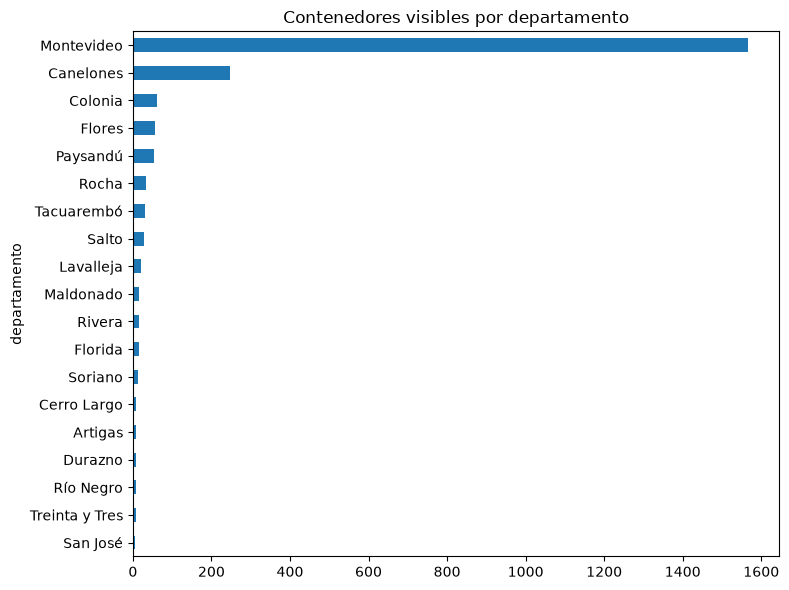

In [30]:
ax = resumen_departamentos.set_index("departamento")["contenedores"].plot.barh(
    figsize=(8, 6), title="Contenedores visibles por departamento"
)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 10. Conclusiones

Las cifras de la conclusión salen de variables calculadas en las celdas anteriores. Antes de mostrarlas, una celda comprueba que coinciden con las que citan `README.md` y `docs/Datos/readme.md`: si los datos cambian, la celda falla y hay que actualizar esos documentos.

In [31]:
cifras = {
    "filas": len(limpio),
    "columnas_original": df_raw.shape[1],
    "columnas_limpio": limpio.shape[1],
    "departamentos_antes": n_departamentos_antes,
    "departamentos_despues": int(limpio["departamento"].nunique()),
    "localidades_antes": n_localidades_antes,
    "localidades_despues": n_localidades_despues,
    "coordenadas_validas_original": n_validas_original,
    "coordenadas_validas_limpio": n_validas_limpio,
    "fuera_de_uruguay_original": n_fuera_original,
    "intercambiadas": n_intercambiadas,
    "visibles": len(visibles),
    "ocultos": n_ocultos,
    "no_publicos": n_no_publicos,
    "marcadores_mapa": n_marcadores,
    "posibles_duplicados": n_posibles_duplicados,
    "repetidas_en_contenido": n_repetidas_contenido,
    "comparten_coordenadas": n_comparten_coordenadas,
    "sospechosas": n_sospechosas,
    "sospechosas_visibles": n_sospechosas_visibles,
    "creados_2020": int(por_anio_creacion.get(2020, 0)),
    "sin_actualizar_un_anio": n_sin_actualizar_un_anio,
    "mediana_dias_sin_actualizar": mediana_dias_sin_actualizar,
    "sin_tipo": n_sin_tipo,
    "montevideo_visibles": len(contenedores_por_departamento["Montevideo"]),
    "canelones_visibles": len(contenedores_por_departamento["Canelones"]),
    "colonia_visibles": len(contenedores_por_departamento["Colonia"]),
    "celdas_modificadas": len(registro_cambios),
    "contenedores_modificados": int(registro_cambios["id"].nunique()),
}

# Cifras que citan README.md y docs/Datos/readme.md
ESPERADAS = {
    "filas": 2423, "columnas_original": 16, "columnas_limpio": 23,
    "departamentos_antes": 28, "departamentos_despues": 19,
    "localidades_antes": 299, "localidades_despues": 261,
    "coordenadas_validas_original": 2372, "coordenadas_validas_limpio": 2417,
    "fuera_de_uruguay_original": 51, "intercambiadas": 44,
    "visibles": 2207, "ocultos": 207, "no_publicos": 9, "marcadores_mapa": 2201,
    "posibles_duplicados": 26, "repetidas_en_contenido": 14, "comparten_coordenadas": 47,
    "sospechosas": 19, "sospechosas_visibles": 16,
    "creados_2020": 1889, "sin_actualizar_un_anio": 1932, "mediana_dias_sin_actualizar": 748, "sin_tipo": 820,
    "montevideo_visibles": 1567, "canelones_visibles": 247, "colonia_visibles": 61,
    "celdas_modificadas": 795, "contenedores_modificados": 640,
}
for nombre, esperado in ESPERADAS.items():
    assert cifras[nombre] == esperado, (nombre, cifras[nombre], esperado)

pct = lambda parte, total: f"{parte / total * 100:.0f} %"
display(Markdown(f"""### Conclusión del EDA de contenedores

- **Resultado:** {cifras['filas']:,} contenedores y {cifras['columnas_original']} columnas en el original; el dataset limpio tiene {cifras['columnas_limpio']} columnas y conserva todas las filas. Se modificaron {len(registro_cambios):,} celdas en {registro_cambios['id'].nunique():,} contenedores, todas en el registro de cambios.
- **Repetidos:** ninguna fila es idéntica y ningún `Id` se repite. {cifras['repetidas_en_contenido']} filas repiten el contenido y {cifras['comparten_coordenadas']} comparten coordenadas exactas. Quedan {cifras['posibles_duplicados']} marcadas como `posible_duplicado`, sin borrar.
- **Coordenadas:** {cifras['fuera_de_uruguay_original']} filas caían fuera de Uruguay o sin coordenadas; {cifras['intercambiadas']} tenían latitud y longitud intercambiadas. Tras la limpieza, {cifras['coordenadas_validas_limpio']:,} tienen coordenadas válidas y {n_sin_coordenadas} quedan sin ellas.
- **Sospechosas:** {cifras['sospechosas']} puntos ({cifras['sospechosas_visibles']} visibles) están lejos de su departamento y sin respaldo de su localidad. Hay que verificarlos; no se modifican.
- **Departamentos y localidades:** {cifras['departamentos_antes']} escrituras de departamento quedan en {cifras['departamentos_despues']}; {cifras['localidades_antes']} localidades quedan en {cifras['localidades_despues']}.
- **Visibilidad:** {cifras['visibles']:,} contenedores son visibles; {cifras['ocultos']} están ocultos y {cifras['no_publicos']} no son públicos. En el mapa hay {cifras['marcadores_mapa']:,} marcadores.
- **Concentración:** Montevideo tiene {cifras['montevideo_visibles']:,} de los {cifras['visibles']:,} visibles ({pct(cifras['montevideo_visibles'], cifras['visibles'])}); sigue Canelones ({cifras['canelones_visibles']}) y Colonia ({cifras['colonia_visibles']}). Muestra dónde están cargados los contenedores, no la cobertura real.
- **Frescura:** {pct(cifras['creados_2020'], cifras['visibles'])} de los visibles se cargó en 2020, y {pct(cifras['sin_actualizar_un_anio'], cifras['visibles'])} llevaba más de un año sin actualizarse al 27/07/2022 (mediana: {cifras['mediana_dias_sin_actualizar']} días).
- **Tipo de sitio:** {pct(cifras['sin_tipo'], cifras['visibles'])} de los visibles no tiene tipo.
- **Trazabilidad:** parquet releído e idéntico; el CSV original no cambió (SHA-256 `{huella_original_antes[:12]}…`).
"""))

### Conclusión del EDA de contenedores

- **Resultado:** 2,423 contenedores y 16 columnas en el original; el dataset limpio tiene 23 columnas y conserva todas las filas. Se modificaron 795 celdas en 640 contenedores, todas en el registro de cambios.
- **Repetidos:** ninguna fila es idéntica y ningún `Id` se repite. 14 filas repiten el contenido y 47 comparten coordenadas exactas. Quedan 26 marcadas como `posible_duplicado`, sin borrar.
- **Coordenadas:** 51 filas caían fuera de Uruguay o sin coordenadas; 44 tenían latitud y longitud intercambiadas. Tras la limpieza, 2,417 tienen coordenadas válidas y 6 quedan sin ellas.
- **Sospechosas:** 19 puntos (16 visibles) están lejos de su departamento y sin respaldo de su localidad. Hay que verificarlos; no se modifican.
- **Departamentos y localidades:** 28 escrituras de departamento quedan en 19; 299 localidades quedan en 261.
- **Visibilidad:** 2,207 contenedores son visibles; 207 están ocultos y 9 no son públicos. En el mapa hay 2,201 marcadores.
- **Concentración:** Montevideo tiene 1,567 de los 2,207 visibles (71 %); sigue Canelones (247) y Colonia (61). Muestra dónde están cargados los contenedores, no la cobertura real.
- **Frescura:** 86 % de los visibles se cargó en 2020, y 88 % llevaba más de un año sin actualizarse al 27/07/2022 (mediana: 748 días).
- **Tipo de sitio:** 37 % de los visibles no tiene tipo.
- **Trazabilidad:** parquet releído e idéntico; el CSV original no cambió (SHA-256 `01ffdfe84b61…`).
